# 06 — Robustness, Uncertainty & Scientific Interpretation

**Target:** MaNGA plate-IFU `8138-12704`  
**DAPTYPE:** `HYB10-MILESHC-MASTARSSP`

## Purpose
This milestone evaluates how sensitive the Milestone 5 results are to data-quality choices and finite sampling. It estimates bootstrap uncertainties for selected quantities, compares standard and strict quality cuts, and creates a structured research-report draft.

## Important distinction
The bootstrap intervals in this notebook quantify **sampling variation among the selected stellar bins**. They do not include every systematic uncertainty (e.g. beam smearing, template mismatch, adopted geometry, inclination, redshift calibration, or the DAP model assumptions). Do not present them as complete measurement uncertainties.

The outputs are intended to support interpretation, not to claim detection of a supermassive-black-hole binary.

## 1. Imports and reproducibility settings

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from datetime import datetime, timezone

RANDOM_SEED = 813812704
N_BOOTSTRAP = 2000
rng = np.random.default_rng(RANDOM_SEED)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "font.size": 10,
})

## 2. Locate the project and load the source products

In [2]:
candidate_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path(r"D:\\KS\\manga-stellar-kinematics"),
]
PROJECT_ROOT = next(
    (p.resolve() for p in candidate_roots
     if (p / "data" / "raw").is_dir()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT manually to your project folder.")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

maps_files = list(RAW_DIR.glob(
    "manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits*"
))
npz_path = PROCESSED_DIR / "stellar_kinematics_8138-12704.npz"
if len(maps_files) != 1:
    raise FileNotFoundError(f"Expected one MAPS file; found {maps_files}")
if not npz_path.exists():
    raise FileNotFoundError("Run Notebook 03 first: processed kinematics NPZ is missing.")

MAPS_PATH = maps_files[0]
kin = np.load(npz_path)
maps = fits.open(MAPS_PATH, memmap=True)

print("Project:", PROJECT_ROOT)
print("MAPS:", MAPS_PATH.name)

Project: D:\KS\manga-stellar-kinematics
MAPS: manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz


## 3. Reconstruct one sample per stellar kinematic bin

In [3]:
required = [
    "STELLAR_VEL", "STELLAR_VEL_IVAR", "STELLAR_VEL_MASK",
    "STELLAR_SIGMA", "STELLAR_SIGMA_IVAR", "STELLAR_SIGMA_MASK",
    "STELLAR_SIGMACORR", "BINID", "BIN_LWSKYCOO",
    "BIN_LWELLCOO", "BIN_MFLUX"
]
available = {h.name.upper() for h in maps}
missing = [name for name in required if name not in available]
if missing:
    raise KeyError(f"Missing required MAPS extensions: {missing}")

vel = np.asarray(maps["STELLAR_VEL"].data, dtype=float)
vel_ivar = np.asarray(maps["STELLAR_VEL_IVAR"].data, dtype=float)
vel_mask = np.asarray(maps["STELLAR_VEL_MASK"].data)
sigma_raw = np.asarray(maps["STELLAR_SIGMA"].data, dtype=float)
sigma_ivar = np.asarray(maps["STELLAR_SIGMA_IVAR"].data, dtype=float)
sigma_mask = np.asarray(maps["STELLAR_SIGMA_MASK"].data)
sigma_inst = np.asarray(maps["STELLAR_SIGMACORR"].data[0], dtype=float)

binid = np.asarray(maps["BINID"].data)
bin_sky = np.asarray(maps["BIN_LWSKYCOO"].data, dtype=float)
bin_ell = np.asarray(maps["BIN_LWELLCOO"].data, dtype=float)
bin_mflux = np.asarray(maps["BIN_MFLUX"].data, dtype=float)

if binid.ndim != 3 or binid.shape[0] < 2:
    raise ValueError("Expected MAPS BINID with stellar-bin plane at index 1.")
if bin_sky.shape[0] != 2 or bin_ell.shape[0] != 4:
    raise ValueError("Unexpected BIN coordinate channel shape.")

stellar_binid = binid[1]
flat = stellar_binid.ravel()
valid_pixels = flat >= 0
unique_ids, first_indices = np.unique(flat[valid_pixels], return_index=True)
valid_flat_indices = np.flatnonzero(valid_pixels)
representative = valid_flat_indices[first_indices]
yy, xx = np.unravel_index(representative, vel.shape)

v = vel[yy, xx]
vi = vel_ivar[yy, xx]
vm = vel_mask[yy, xx]
sraw = sigma_raw[yy, xx]
si = sigma_inst[yy, xx]
sivar = sigma_ivar[yy, xx]
sm = sigma_mask[yy, xx]
x = bin_sky[0, yy, xx]
y = bin_sky[1, yy, xx]
r_re = bin_ell[1, yy, xx]
r_arcsec = bin_ell[0, yy, xx]
flux = bin_mflux[yy, xx]

print("Unique stellar bins:", len(unique_ids))

Unique stellar bins: 2194


## 4. Define standard and strict quality samples

In [4]:
DAP_BITS = {
    "NOCOV": 0, "LOWCOV": 1, "DEADFIBER": 2, "FORESTAR": 3,
    "NOVALUE": 4, "UNRELIABLE": 5, "MATHERROR": 6,
    "FITFAILED": 7, "NEARBOUND": 8, "NOCORRECTION": 9,
    "DONOTUSE": 30,
}
def has_any_flag(mask_values, names):
    bitmask = 0
    for name in names:
        bitmask |= 1 << DAP_BITS[name]
    return (mask_values.astype(np.uint64) & np.uint64(bitmask)) != 0

base_exclusions = ["NOCOV", "NOVALUE", "MATHERROR", "FITFAILED", "DONOTUSE"]
extra_exclusions = [
    "LOWCOV", "DEADFIBER", "FORESTAR", "UNRELIABLE",
    "NEARBOUND", "NOCORRECTION"
]

v_finite = (
    np.isfinite(v) & np.isfinite(vi) & (vi > 0)
    & np.isfinite(x) & np.isfinite(y)
    & np.isfinite(r_re) & (r_re >= 0)
)
sigma_sq = sraw**2 - si**2
s_finite = (
    np.isfinite(sraw) & np.isfinite(si) & np.isfinite(sivar)
    & (sivar > 0) & (si >= 0) & (sigma_sq >= 0)
)
sigma = np.full_like(sraw, np.nan, dtype=float)
sigma[s_finite] = np.sqrt(sigma_sq[s_finite])

v_standard = v_finite & ~has_any_flag(vm, base_exclusions)
s_standard = s_finite & ~has_any_flag(sm, base_exclusions)
v_strict = v_finite & ~has_any_flag(vm, base_exclusions + extra_exclusions)
s_strict = s_finite & ~has_any_flag(sm, base_exclusions + extra_exclusions)

common = (
    np.isfinite(flux) & (flux > 0)
    & np.isfinite(r_re) & (r_re >= 0)
    & np.isfinite(x) & np.isfinite(y)
)
joint_standard = v_standard & s_standard & common
joint_strict = v_strict & s_strict & common

print("Standard joint bins:", joint_standard.sum())
print("Strict joint bins:", joint_strict.sum())
if joint_standard.sum() < 8:
    raise RuntimeError("Too few standard joint bins for uncertainty analysis.")
if joint_strict.sum() < 8:
    print("WARNING: strict sample has fewer than 8 bins; strict bootstrap may be unstable.")

Standard joint bins: 2194
Strict joint bins: 2194


## 5. Define analysis functions

In [5]:
def weighted_plane_pa(vv, xx, yy, ivar):
    good = (
        np.isfinite(vv) & np.isfinite(xx) & np.isfinite(yy)
        & np.isfinite(ivar) & (ivar > 0)
    )
    if good.sum() < 3:
        return np.nan, np.nan
    design = np.column_stack([xx[good], yy[good], np.ones(good.sum())])
    weights = np.sqrt(ivar[good] / np.nanmedian(ivar[good]))
    coef, *_ = np.linalg.lstsq(design * weights[:, None],
                               vv[good] * weights, rcond=None)
    gx, gy = coef[0], coef[1]
    pa = np.degrees(np.arctan2(gx, gy)) % 180
    return pa, np.hypot(gx, gy)

def lambda_r(radius, flux_values, velocity, dispersion, aperture_re):
    good = (
        np.isfinite(radius) & (radius <= aperture_re)
        & np.isfinite(flux_values) & (flux_values > 0)
        & np.isfinite(velocity) & np.isfinite(dispersion)
    )
    if good.sum() == 0:
        return np.nan
    numerator = np.sum(
        flux_values[good] * radius[good] * np.abs(velocity[good])
    )
    denominator = np.sum(
        flux_values[good] * radius[good]
        * np.sqrt(velocity[good]**2 + dispersion[good]**2)
    )
    return numerator / denominator if denominator > 0 else np.nan

def estimate_metrics(mask):
    if mask.sum() < 6:
        return None
    vsys = np.nanmedian(v[mask])
    vres = v - vsys
    pa, grad = weighted_plane_pa(v[mask], x[mask], y[mask], vi[mask])
    p5, p95 = np.nanpercentile(vres[mask], [5, 95])
    vrot = 0.5 * (p95 - p5)
    lam1 = lambda_r(r_re[mask], flux[mask], vres[mask], sigma[mask], 1.0)
    lam2 = lambda_r(r_re[mask], flux[mask], vres[mask], sigma[mask], 2.0)
    return {
        "n_bins": int(mask.sum()),
        "v_sys_residual_kms": float(vsys),
        "kinematic_pa_deg_mod180": float(pa),
        "velocity_gradient_kms_per_arcsec": float(grad),
        "vrot_projected_proxy_kms": float(vrot),
        "lambda_R_1Re": float(lam1),
        "lambda_R_2Re": float(lam2),
    }

standard_metrics = estimate_metrics(joint_standard)
strict_metrics = estimate_metrics(joint_strict)
print("Standard:", standard_metrics)
print("Strict:", strict_metrics)

Standard: {'n_bins': 2194, 'v_sys_residual_kms': 33.64405632019043, 'kinematic_pa_deg_mod180': 167.30031298907772, 'velocity_gradient_kms_per_arcsec': 20.276669374368016, 'vrot_projected_proxy_kms': 206.83420333862307, 'lambda_R_1Re': 0.64621489194598, 'lambda_R_2Re': 0.7155977178959942}
Strict: {'n_bins': 2194, 'v_sys_residual_kms': 33.64405632019043, 'kinematic_pa_deg_mod180': 167.30031298907772, 'velocity_gradient_kms_per_arcsec': 20.276669374368016, 'vrot_projected_proxy_kms': 206.83420333862307, 'lambda_R_1Re': 0.64621489194598, 'lambda_R_2Re': 0.7155977178959942}


## 6. Bootstrap sampling uncertainty

In [6]:
def bootstrap_metrics(mask, n_boot=N_BOOTSTRAP):
    idx = np.flatnonzero(mask)
    if len(idx) < 8:
        raise ValueError("At least 8 valid bins are required for this bootstrap.")
    names = [
        "v_sys_residual_kms",
        "kinematic_pa_deg_mod180",
        "velocity_gradient_kms_per_arcsec",
        "vrot_projected_proxy_kms",
        "lambda_R_1Re",
        "lambda_R_2Re",
    ]
    samples = {name: [] for name in names}
    for _ in range(n_boot):
        draw = rng.choice(idx, size=len(idx), replace=True)
        # Repeated sampled bins are valid bootstrap resamples.
        vsys = np.nanmedian(v[draw])
        vres = v[draw] - vsys
        pa, grad = weighted_plane_pa(v[draw], x[draw], y[draw], vi[draw])
        p5, p95 = np.nanpercentile(vres, [5, 95])
        vals = {
            "v_sys_residual_kms": vsys,
            "kinematic_pa_deg_mod180": pa,
            "velocity_gradient_kms_per_arcsec": grad,
            "vrot_projected_proxy_kms": 0.5 * (p95 - p5),
            "lambda_R_1Re": lambda_r(r_re[draw], flux[draw], vres, sigma[draw], 1.0),
            "lambda_R_2Re": lambda_r(r_re[draw], flux[draw], vres, sigma[draw], 2.0),
        }
        for name, value in vals.items():
            if np.isfinite(value):
                samples[name].append(value)
    return {k: np.asarray(val) for k, val in samples.items()}

boot_standard = bootstrap_metrics(joint_standard)
boot_strict = bootstrap_metrics(joint_strict)

## 7. Summarize bootstrap intervals

In [7]:
def percentile_summary(samples):
    rows = []
    for name, values in samples.items():
        if len(values) == 0:
            rows.append((name, np.nan, np.nan, np.nan, 0))
        else:
            lo, med, hi = np.nanpercentile(values, [16, 50, 84])
            rows.append((name, med, lo, hi, len(values)))
    return rows

standard_ci = percentile_summary(boot_standard)
strict_ci = percentile_summary(boot_strict)

print("STANDARD SAMPLE — bootstrap median and 16th/84th percentiles")
for row in standard_ci:
    print(f"{row[0]:38s} median={row[1]:.4f}, 16-84%=[{row[2]:.4f}, {row[3]:.4f}], Nboot={row[4]}")

print("\nSTRICT SAMPLE — bootstrap median and 16th/84th percentiles")
for row in strict_ci:
    print(f"{row[0]:38s} median={row[1]:.4f}, 16-84%=[{row[2]:.4f}, {row[3]:.4f}], Nboot={row[4]}")

STANDARD SAMPLE — bootstrap median and 16th/84th percentiles
v_sys_residual_kms                     median=33.7738, 16-84%=[26.6949, 38.5799], Nboot=2000
kinematic_pa_deg_mod180                median=167.3068, 16-84%=[166.8768, 167.7393], Nboot=2000
velocity_gradient_kms_per_arcsec       median=20.2696, 16-84%=[20.1185, 20.4209], Nboot=2000
vrot_projected_proxy_kms               median=206.7814, 16-84%=[205.9174, 207.5738], Nboot=2000
lambda_R_1Re                           median=0.6459, 16-84%=[0.6373, 0.6549], Nboot=2000
lambda_R_2Re                           median=0.7155, 16-84%=[0.7098, 0.7211], Nboot=2000

STRICT SAMPLE — bootstrap median and 16th/84th percentiles
v_sys_residual_kms                     median=33.9234, 16-84%=[26.8003, 38.5799], Nboot=2000
kinematic_pa_deg_mod180                median=167.3046, 16-84%=[166.8824, 167.7448], Nboot=2000
velocity_gradient_kms_per_arcsec       median=20.2781, 16-84%=[20.1224, 20.4436], Nboot=2000
vrot_projected_proxy_kms               

## 8. Compare standard and strict quality-cut results

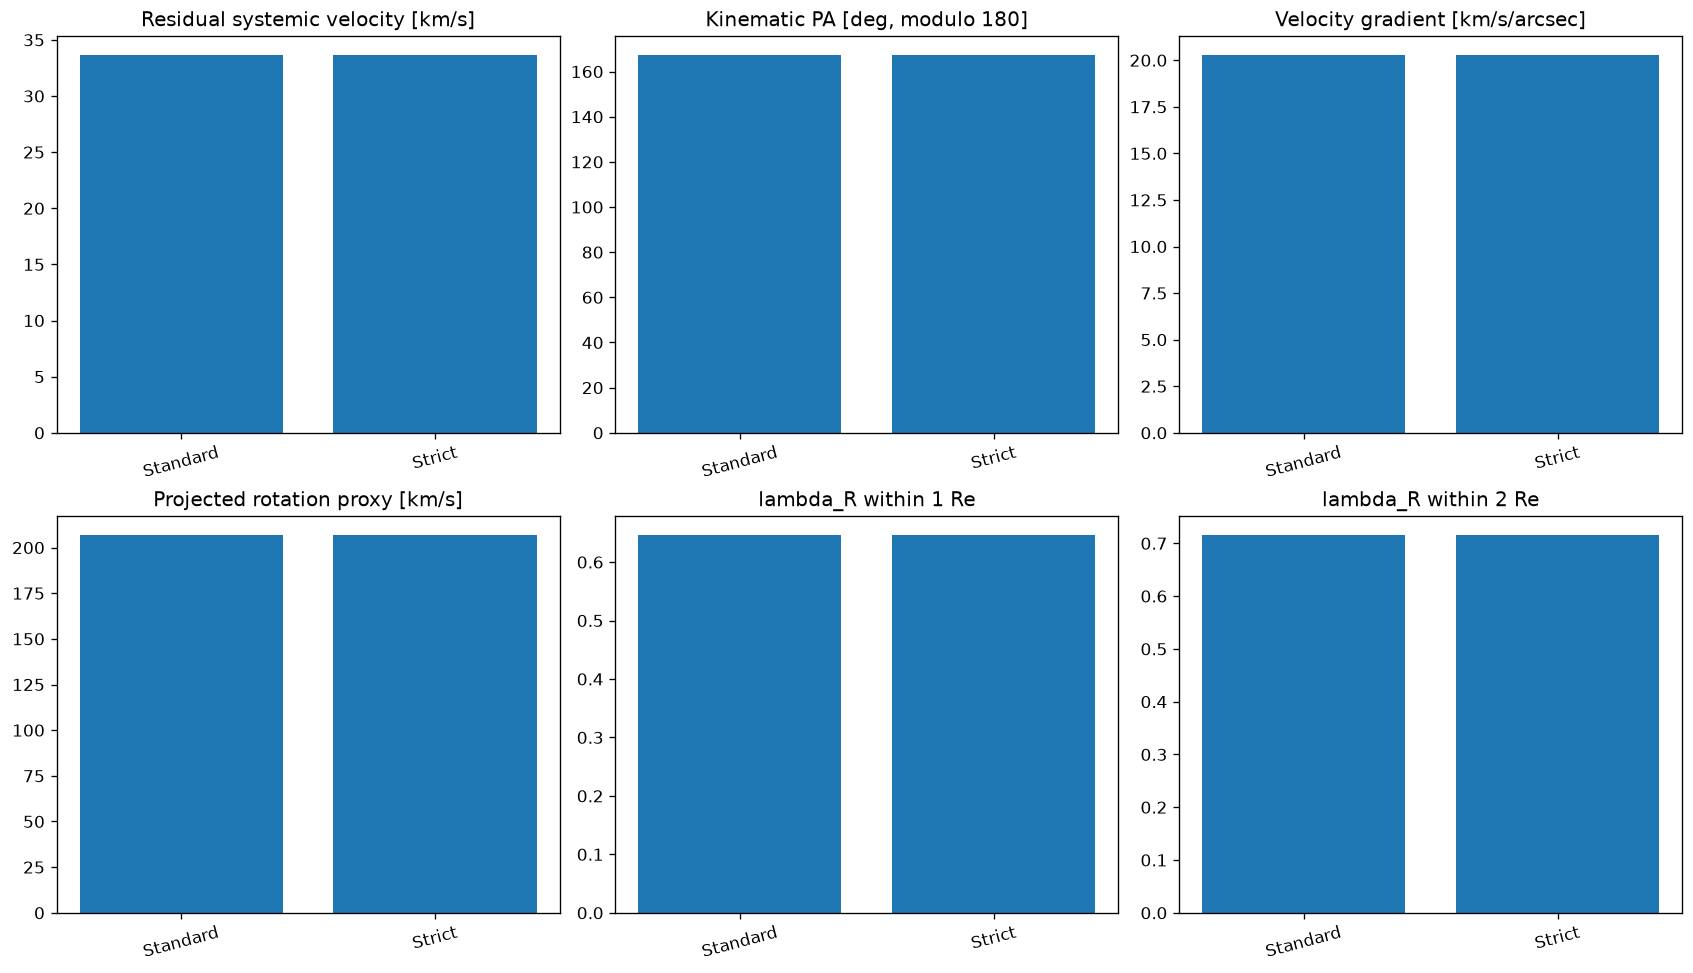

In [8]:
metric_names = [
    "v_sys_residual_kms",
    "kinematic_pa_deg_mod180",
    "velocity_gradient_kms_per_arcsec",
    "vrot_projected_proxy_kms",
    "lambda_R_1Re",
    "lambda_R_2Re",
]
labels = [
    "Residual systemic velocity [km/s]",
    "Kinematic PA [deg, modulo 180]",
    "Velocity gradient [km/s/arcsec]",
    "Projected rotation proxy [km/s]",
    "lambda_R within 1 Re",
    "lambda_R within 2 Re",
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for ax, key, label in zip(axes.flat, metric_names, labels):
    vals = [standard_metrics[key], strict_metrics[key]]
    ax.bar(["Standard", "Strict"], vals)
    ax.set_title(label)
    ax.tick_params(axis="x", rotation=15)
plt.show()

## 9. Visualize bootstrap distributions

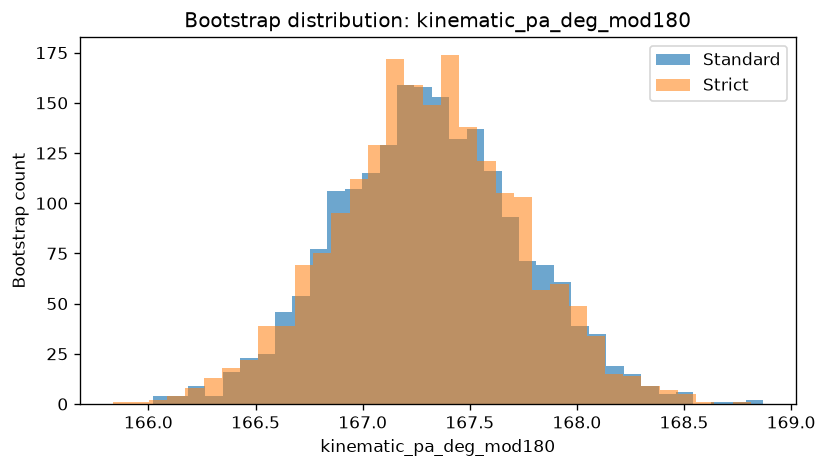

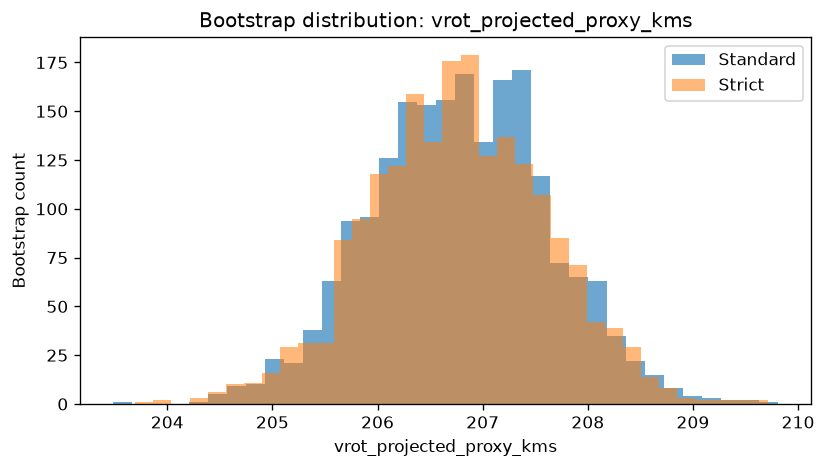

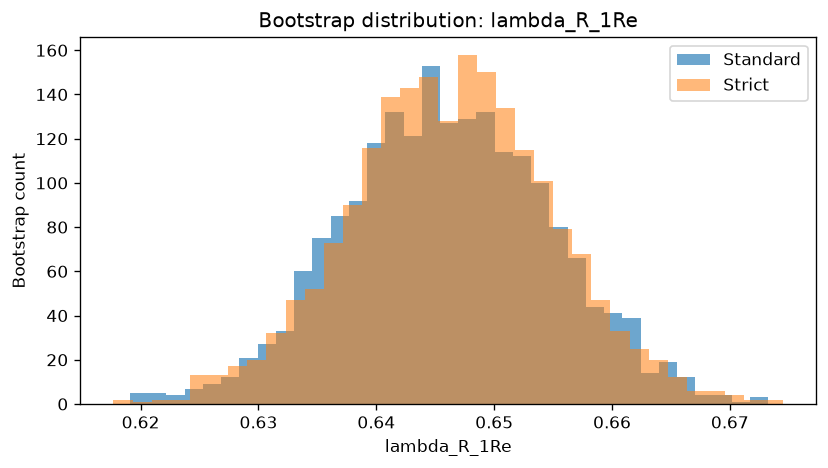

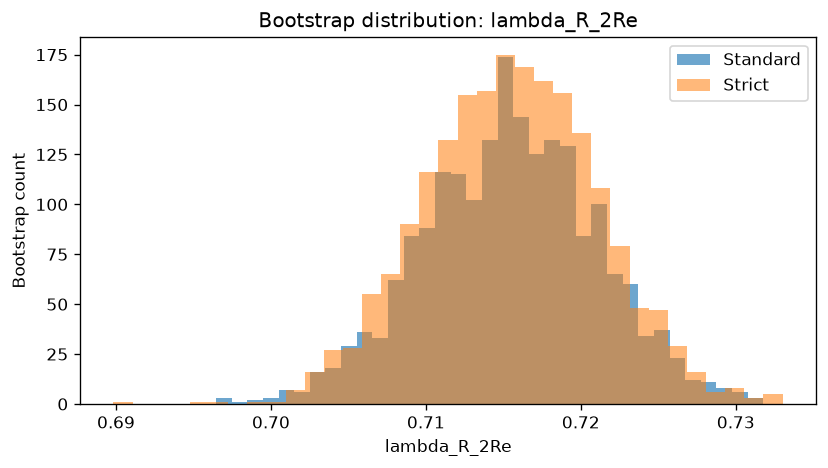

In [9]:
for key in [
    "kinematic_pa_deg_mod180",
    "vrot_projected_proxy_kms",
    "lambda_R_1Re",
    "lambda_R_2Re",
]:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(boot_standard[key], bins=35, alpha=0.65, label="Standard")
    ax.hist(boot_strict[key], bins=35, alpha=0.55, label="Strict")
    ax.set_title(f"Bootstrap distribution: {key}")
    ax.set_xlabel(key)
    ax.set_ylabel("Bootstrap count")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"bootstrap_{key}.png", bbox_inches="tight")
    plt.show()

## 10. Record methodological/systematic limitations

In [10]:
limitations = [
    "Sampling bootstrap intervals quantify bin-sampling variation only.",
    "They do not include systematic uncertainty from beam smearing or PSF convolution.",
    "They do not include stellar-template mismatch or DAP model assumptions.",
    "The adopted photometric geometry affects elliptical radii and lambda_R.",
    "The first-order velocity-plane PA can be biased by non-circular motions, bars, or asymmetry.",
    "The projected rotation amplitude is not the deprojected circular speed.",
    "The residual systemic velocity is relative to the DAP input guess redshift.",
    "The lambda_R estimator is projected and aperture-dependent.",
    "A stellar kinematic map alone is not evidence for a supermassive-black-hole binary."
]
for item in limitations:
    print("-", item)

- Sampling bootstrap intervals quantify bin-sampling variation only.
- They do not include systematic uncertainty from beam smearing or PSF convolution.
- They do not include stellar-template mismatch or DAP model assumptions.
- The adopted photometric geometry affects elliptical radii and lambda_R.
- The first-order velocity-plane PA can be biased by non-circular motions, bars, or asymmetry.
- The projected rotation amplitude is not the deprojected circular speed.
- The residual systemic velocity is relative to the DAP input guess redshift.
- The lambda_R estimator is projected and aperture-dependent.
- A stellar kinematic map alone is not evidence for a supermassive-black-hole binary.


## 11. Save numerical robustness outputs

In [11]:
def write_metric_block(label, metrics, ci_rows):
    lines = [label]
    if metrics is None:
        return lines + ["Insufficient valid bins."]
    for key, value in metrics.items():
        lines.append(f"{key}: {value}")
    lines.append("Bootstrap percentile intervals (16th, 50th, 84th):")
    for name, med, lo, hi, nboot in ci_rows:
        lines.append(
            f"{name}: {med:.6g}, {lo:.6g}, {hi:.6g} (valid resamples={nboot})"
        )
    return lines

report_lines = [
    "MaNGA Robustness and Uncertainty Report",
    "Plate-IFU: 8138-12704",
    "DAPTYPE: HYB10-MILESHC-MASTARSSP",
    f"Generated UTC: {datetime.now(timezone.utc).isoformat()}",
    f"Bootstrap iterations requested: {N_BOOTSTRAP}",
    f"Random seed: {RANDOM_SEED}",
    "",
]
report_lines += write_metric_block("STANDARD QUALITY SAMPLE", standard_metrics, standard_ci)
report_lines += [""]
report_lines += write_metric_block("STRICT QUALITY SAMPLE", strict_metrics, strict_ci)
report_lines += ["", "LIMITATIONS"] + [f"- {x}" for x in limitations]

report_path = OUTPUT_DIR / "robustness_uncertainty_report.txt"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print("Saved:", report_path)

Saved: D:\KS\manga-stellar-kinematics\outputs\robustness_uncertainty_report.txt


## 12. Create a research-report draft with explicit placeholders

In [12]:
def fmt(value, digits=2):
    return "NOT AVAILABLE" if value is None or not np.isfinite(value) else f"{value:.{digits}f}"

draft = f'''# Stellar Kinematics of MaNGA Target 8138-12704

## Data
The analysis uses the MaNGA MAPS product for plate-IFU 8138-12704,
with DAPTYPE HYB10-MILESHC-MASTARSSP. Stellar kinematic measurements
are treated as Voronoi-bin measurements, with one representative
measurement retained per stellar bin.

## Methods
Stellar line-of-sight velocities and velocity dispersions were extracted
from the MAPS product. The velocity dispersion was corrected using
the first channel of STELLAR_SIGMACORR:
sigma_corrected = sqrt(sigma_raw^2 - sigma_instrumental^2).
Measurements were filtered using DAP quality flags and positive inverse
variance. A weighted first-order plane was fitted to estimate the
large-scale velocity gradient and a preliminary kinematic position angle.
Radial profiles and a projected lambda_R estimator were calculated
using the adopted DAP elliptical coordinates.

## Preliminary measurements
- Number of unique stellar bins: {len(unique_ids)}
- Standard joint-valid bins: {joint_standard.sum()}
- Strict joint-valid bins: {joint_strict.sum()}
- Residual velocity relative to DAP input guess: {fmt(standard_metrics['v_sys_residual_kms'])} km/s
- First-order kinematic PA: {fmt(standard_metrics['kinematic_pa_deg_mod180'])} degrees (modulo 180)
- Projected rotation amplitude proxy: {fmt(standard_metrics['vrot_projected_proxy_kms'])} km/s
- lambda_R within 1 Re: {fmt(standard_metrics['lambda_R_1Re'], 4)}
- lambda_R within 2 Re: {fmt(standard_metrics['lambda_R_2Re'], 4)}

## Robustness
Compare the standard and strict quality-cut results in the accompanying
robustness report. Bootstrap intervals quantify sampling variation among
the selected bins and do not include the full systematic error budget.

## Interpretation — complete after inspecting the figures
[Describe whether the velocity field is regular, whether the fitted
kinematic axis agrees with the map, and whether the dispersion profile
shows a central enhancement or other structure. Do not infer features
that are not visible or statistically supported.]

## Relevance to the candidate SMBH-binary host-galaxy question
[Explain what the measured large-scale stellar kinematics do and do not
constrain. These MaNGA measurements alone cannot establish the presence
of a close SMBH binary. State what independent evidence and higher
spatial/spectral resolution follow-up would be needed.]

## Limitations
[Discuss spatial resolution/PSF, inclination and geometry assumptions,
template mismatch, DAP binning, mask sensitivity, radial coverage,
and systematic uncertainties.]
'''

draft_path = OUTPUT_DIR / "research_report_draft_8138-12704.md"
draft_path.write_text(draft, encoding="utf-8")
print("Saved:", draft_path)
print("\n".join(draft.splitlines()[:30]))

Saved: D:\KS\manga-stellar-kinematics\outputs\research_report_draft_8138-12704.md
# Stellar Kinematics of MaNGA Target 8138-12704

## Data
The analysis uses the MaNGA MAPS product for plate-IFU 8138-12704,
with DAPTYPE HYB10-MILESHC-MASTARSSP. Stellar kinematic measurements
are treated as Voronoi-bin measurements, with one representative
measurement retained per stellar bin.

## Methods
Stellar line-of-sight velocities and velocity dispersions were extracted
from the MAPS product. The velocity dispersion was corrected using
the first channel of STELLAR_SIGMACORR:
sigma_corrected = sqrt(sigma_raw^2 - sigma_instrumental^2).
Measurements were filtered using DAP quality flags and positive inverse
variance. A weighted first-order plane was fitted to estimate the
large-scale velocity gradient and a preliminary kinematic position angle.
Radial profiles and a projected lambda_R estimator were calculated
using the adopted DAP elliptical coordinates.

## Preliminary measurements
- Number of uniq

## 13. Close files

In [13]:
maps.close()
kin.close()
print("MAPS FITS and processed NPZ files closed.")

MAPS FITS and processed NPZ files closed.


## 14. Milestone 6 checklist

- [ ] Standard and strict quality samples compared.
- [ ] Bootstrap sampling intervals calculated.
- [ ] Bootstrap distributions inspected for PA, rotation proxy, and lambda_R.
- [ ] Systematic limitations recorded.
- [ ] Robustness report saved.
- [ ] Research-report draft generated with explicit interpretation placeholders.

### Scientific decision gate
Do not finalize the research interpretation until you have inspected:
1. The WCS velocity map and the first-order fitted velocity plane.
2. The corrected velocity-dispersion map and radial profile.
3. Standard-versus-strict mask sensitivity.
4. The bootstrap distributions and number of valid bins.

**Next step:** review your actual plots and report values together, then decide whether the dataset supports a defensible description of the host galaxy's large-scale stellar kinematics.